[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhconning/hunter_eco701/blob/main/notebooks/topic03_production_figures.ipynb)

# Topic 3: Production Optimization -- Figure Generator

Regenerates every static figure used in
[`slides/03_production-optimization/deck.qmd`](../slides/03_production-optimization/deck.qmd)
from its underlying formulas, replacing the legacy PowerPoint slide crops
that the Marp version of this deck inherited.

Same conventions as the Topic 2 figure notebook: navy/amber palette, serif
type, saved at 150 dpi into `../slides/03_production-optimization/figs/`.

Throughout, the technology is Cobb-Douglas $q = K^{1/2} L^{1/2}$ unless a
figure says otherwise, the wage is $w$ and the rental rate of capital is $r$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY = "#24325c"
AMBER = "#b8842a"
GREY = "#8a8a8a"

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#222222",
})

FIGDIR = Path("../slides/03_production-optimization/figs")
FIGDIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    path = FIGDIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path}")

## Technology: from discrete techniques to a smooth isoquant

saved ..\slides\03_production-optimization\figs\discrete-to-smooth-isoquant.png


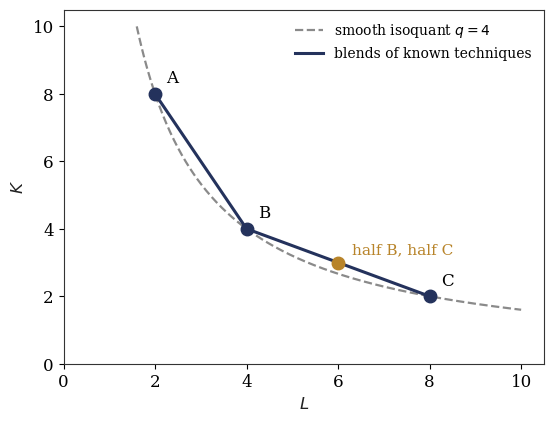

In [2]:
# Three known recipes for the same output, plus the blends between them.
tech = {"A": (2.0, 8.0), "B": (4.0, 4.0), "C": (8.0, 2.0)}   # (L, K)

fig, ax = plt.subplots(figsize=(6.2, 4.6))
L = np.linspace(1.6, 10, 300)
ax.plot(L, 16 / L, color=GREY, lw=1.6, ls="--", label="smooth isoquant $q=4$")
pts = np.array([tech[k] for k in "ABC"])
ax.plot(pts[:, 0], pts[:, 1], "-", color=NAVY, lw=2.2,
        label="blends of known techniques")
ax.plot(pts[:, 0], pts[:, 1], "o", color=NAVY, ms=9, zorder=5)
for k, (l, kk) in tech.items():
    ax.annotate(k, (l, kk), textcoords="offset points", xytext=(8, 8), fontsize=12)
mid = (tech["B"][0] + tech["C"][0]) / 2, (tech["B"][1] + tech["C"][1]) / 2
ax.plot(*mid, "o", color=AMBER, ms=9, zorder=6)
ax.annotate("half B, half C", mid, textcoords="offset points", xytext=(10, 6),
            fontsize=11, color=AMBER)
ax.set_xlim(0, 10.5); ax.set_ylim(0, 10.5)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
ax.legend(frameon=False, fontsize=10, loc="upper right")
savefig(fig, "discrete-to-smooth-isoquant.png")
plt.show()

saved ..\slides\03_production-optimization\figs\isoquant-map.png


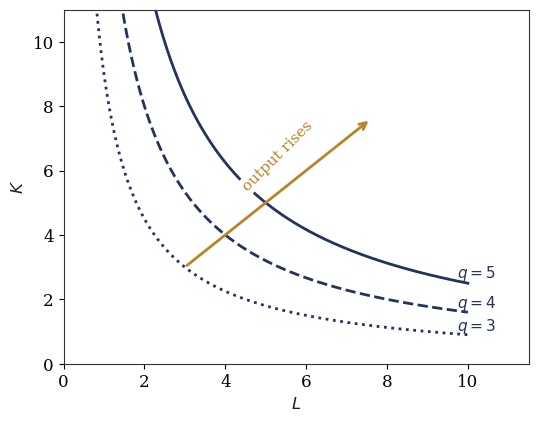

In [3]:
# Isoquant map: higher output to the northeast.
fig, ax = plt.subplots(figsize=(6.0, 4.6))
L = np.linspace(0.6, 10, 400)
for q, style in [(3, ":"), (4, "--"), (5, "-")]:
    ax.plot(L, q**2 / L, color=NAVY, lw=2.0, ls=style)
    ax.annotate(f"$q={q}$", (9.6, q**2 / 9.6), fontsize=11, color=NAVY,
                textcoords="offset points", xytext=(4, 2))
ax.annotate("", xy=(7.6, 7.6), xytext=(3.0, 3.0),
            arrowprops=dict(arrowstyle="->", color=AMBER, lw=2))
ax.annotate("output rises", (5.3, 5.3), color=AMBER, fontsize=11, rotation=45,
            ha="center", va="bottom",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
ax.set_xlim(0, 11.5); ax.set_ylim(0, 11)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
savefig(fig, "isoquant-map.png")
plt.show()

saved ..\slides\03_production-optimization\figs\mrts-diminishing.png


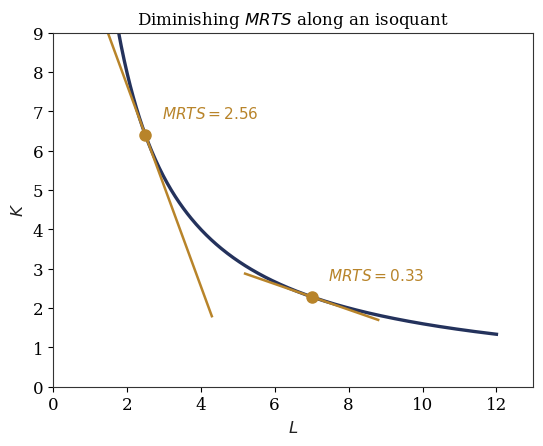

In [4]:
# Diminishing MRTS: tangent lines flatten as L rises along one isoquant.
q = 4.0
L = np.linspace(1.2, 12, 400)
K = q**2 / L

fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.plot(L, K, color=NAVY, lw=2.4)
for L0, colr in [(2.5, AMBER), (7.0, AMBER)]:
    K0 = q**2 / L0
    slope = -q**2 / L0**2                      # dK/dL along the isoquant
    seg = np.linspace(L0 - 1.8, L0 + 1.8, 2)
    ax.plot(seg, K0 + slope * (seg - L0), color=colr, lw=1.8)
    ax.plot(L0, K0, "o", color=colr, ms=8, zorder=5)
    ax.annotate(f"$MRTS = {-slope:.2f}$", (L0, K0), textcoords="offset points",
                xytext=(12, 12), fontsize=11, color=colr)
ax.set_xlim(0, 13); ax.set_ylim(0, 9)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
ax.set_title("Diminishing $MRTS$ along an isoquant", fontsize=12)
savefig(fig, "mrts-diminishing.png")
plt.show()

## Cost minimization: isocost lines, the tangency, the expansion path

saved ..\slides\03_production-optimization\figs\isocost-family.png


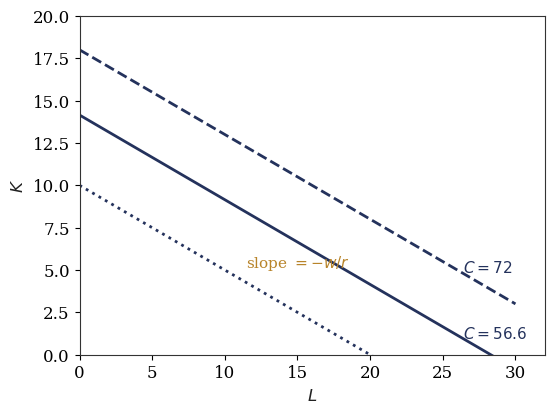

In [5]:
# A family of parallel isocost lines, slope -w/r.
w, r = 2.0, 4.0
fig, ax = plt.subplots(figsize=(6.0, 4.4))
L = np.linspace(0, 30, 200)
for C, style in [(40, ":"), (56.6, "-"), (72, "--")]:
    ax.plot(L, C / r - (w / r) * L, color=NAVY, lw=2.0, ls=style)
    ax.annotate(f"$C={C:g}$", (26, C / r - (w / r) * 26), fontsize=11,
                color=NAVY, textcoords="offset points", xytext=(4, -2))
ax.annotate(r"slope $=-w/r$", (12, 40 / r - (w / r) * 12),
            textcoords="offset points", xytext=(-6, 14), fontsize=11, color=AMBER)
ax.set_xlim(0, 32); ax.set_ylim(0, 20)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
savefig(fig, "isocost-family.png")
plt.show()

saved ..\slides\03_production-optimization\figs\cost-min-tangency.png


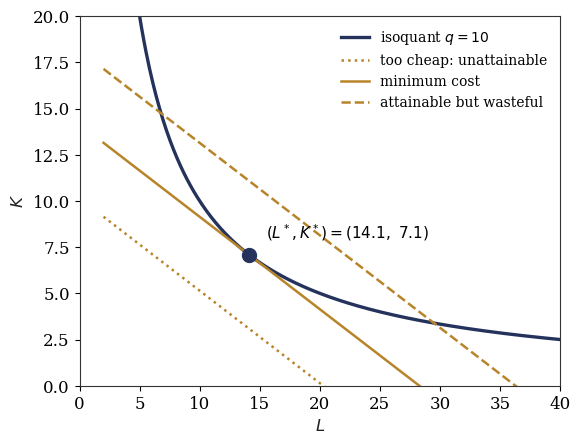

L*=14.142  K*=7.071  C*=56.569


In [6]:
# The cost-minimizing input choice for a given output.
w, r, q = 2.0, 4.0, 10.0
# tangency: MRTS = K/L = w/r  ->  K = (w/r) L ; and K*L = q^2
Lstar = q / np.sqrt(w / r)
Kstar = (w / r) * Lstar
Cstar = w * Lstar + r * Kstar

fig, ax = plt.subplots(figsize=(6.2, 4.8))
L = np.linspace(2, 40, 400)
ax.plot(L, q**2 / L, color=NAVY, lw=2.4, label=f"isoquant $q={q:g}$")
for C, style, lab in [(Cstar - 16, ":", "too cheap: unattainable"),
                      (Cstar, "-", "minimum cost"),
                      (Cstar + 16, "--", "attainable but wasteful")]:
    ax.plot(L, C / r - (w / r) * L, color=AMBER, lw=1.8, ls=style, label=lab)
ax.plot(Lstar, Kstar, "o", color=NAVY, ms=10, zorder=6)
ax.annotate(rf"$(L^*,K^*)=({Lstar:.1f},\ {Kstar:.1f})$", (Lstar, Kstar),
            textcoords="offset points", xytext=(12, 12), fontsize=11)
ax.set_xlim(0, 40); ax.set_ylim(0, 20)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
ax.legend(frameon=False, fontsize=10, loc="upper right")
savefig(fig, "cost-min-tangency.png")
plt.show()
print(f"L*={Lstar:.3f}  K*={Kstar:.3f}  C*={Cstar:.3f}")

saved ..\slides\03_production-optimization\figs\expansion-path.png


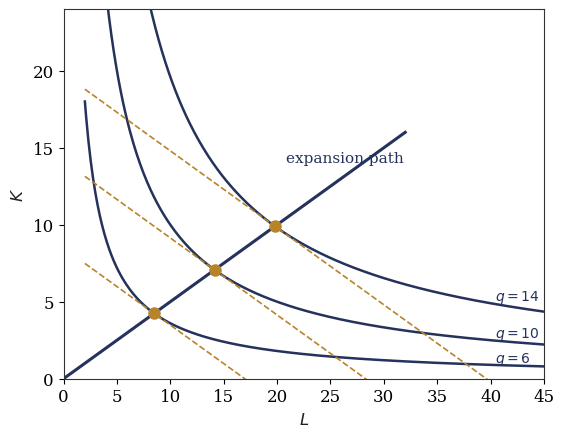

In [7]:
# Expansion path: tangencies for a sequence of output levels.
w, r = 2.0, 4.0
fig, ax = plt.subplots(figsize=(6.2, 4.8))
L = np.linspace(2, 45, 400)
for q in (6, 10, 14):
    ax.plot(L, q**2 / L, color=NAVY, lw=1.8)
    Ls = q / np.sqrt(w / r); Ks = (w / r) * Ls
    C = w * Ls + r * Ks
    ax.plot(L, C / r - (w / r) * L, color=AMBER, lw=1.2, ls="--")
    ax.plot(Ls, Ks, "o", color=AMBER, ms=8, zorder=6)
    ax.annotate(f"$q={q}$", (40, q**2 / 40), fontsize=10, color=NAVY,
                textcoords="offset points", xytext=(3, 2))
Lp = np.linspace(0, 32, 10)
ax.plot(Lp, (w / r) * Lp, color=NAVY, lw=2.2, ls="-")
ax.annotate("expansion path", (26, (w / r) * 26), color=NAVY, fontsize=11,
            textcoords="offset points", xytext=(-40, 12))
ax.set_xlim(0, 45); ax.set_ylim(0, 24)
ax.set_xlabel("$L$"); ax.set_ylabel("$K$")
savefig(fig, "expansion-path.png")
plt.show()

## Returns to scale and the shape of cost

For Cobb-Douglas $F=K^\alpha L^\beta$ the cost function is proportional to
$q^{1/(\alpha+\beta)}$: linear under constant returns, convex under
decreasing returns, concave under increasing returns.

saved ..\slides\03_production-optimization\figs\returns-to-scale-costs.png


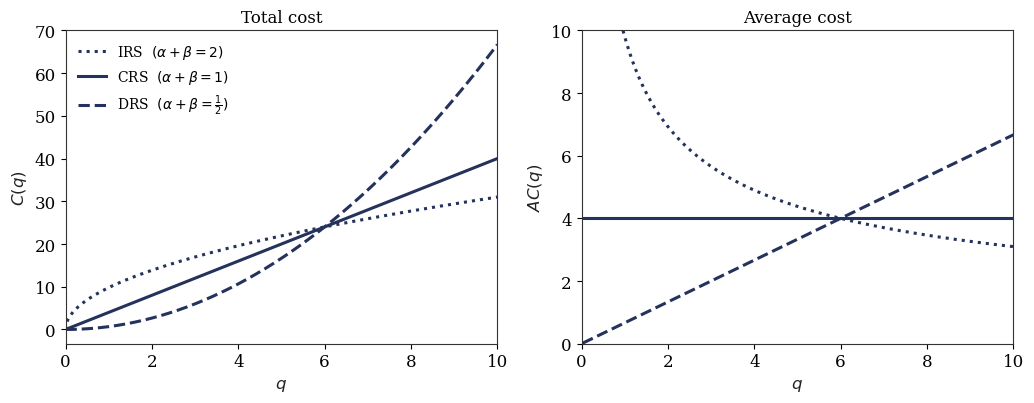

In [8]:
q = np.linspace(0, 10, 400)
cases = [("IRS  $(\\alpha+\\beta=2)$", 0.5, ":"),
         ("CRS  $(\\alpha+\\beta=1)$", 1.0, "-"),
         ("DRS  $(\\alpha+\\beta=\\frac{1}{2})$", 2.0, "--")]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for lab, power, style in cases:
    C = 24 * (q / 6) ** power                 # scaled so the three meet at q=6
    axes[0].plot(q, C, color=NAVY, lw=2.2, ls=style, label=lab)
    with np.errstate(divide="ignore", invalid="ignore"):
        AC = np.where(q > 0, C / q, np.nan)
    axes[1].plot(q, AC, color=NAVY, lw=2.2, ls=style, label=lab)
axes[0].set_xlabel("$q$"); axes[0].set_ylabel("$C(q)$")
axes[0].set_title("Total cost", fontsize=12)
axes[0].legend(frameon=False, fontsize=10, loc="upper left")
axes[1].set_xlabel("$q$"); axes[1].set_ylabel("$AC(q)$")
axes[1].set_title("Average cost", fontsize=12)
axes[1].set_ylim(0, 10)
for ax in axes:
    ax.set_xlim(0, 10)
fig.tight_layout()
savefig(fig, "returns-to-scale-costs.png")
plt.show()

saved ..\slides\03_production-optimization\figs\ac-mc-fixed-costs.png


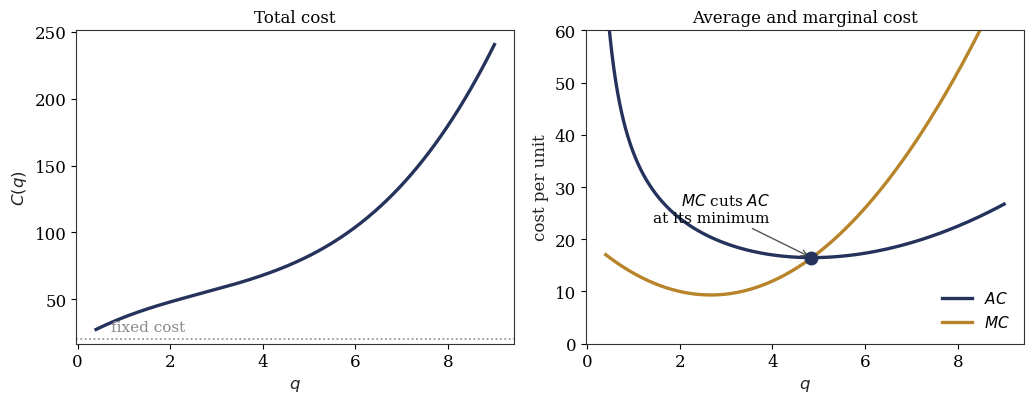

AC minimised at q = 4.84


In [9]:
# U-shaped AC and MC with a fixed cost: MC cuts AC at AC's minimum.
FC = 20.0
q = np.linspace(0.4, 9, 400)
C = FC + 0.5 * q**3 - 4 * q**2 + 20 * q
MC = 1.5 * q**2 - 8 * q + 20
AC = C / q
qmin = q[np.nanargmin(AC)]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
axes[0].plot(q, C, color=NAVY, lw=2.4)
axes[0].axhline(FC, color=GREY, lw=1.2, ls=":")
axes[0].annotate("fixed cost", (0.6, FC), textcoords="offset points",
                 xytext=(4, 6), fontsize=11, color=GREY)
axes[0].set_xlabel("$q$"); axes[0].set_ylabel("$C(q)$")
axes[0].set_title("Total cost", fontsize=12)

axes[1].plot(q, AC, color=NAVY, lw=2.4, label="$AC$")
axes[1].plot(q, MC, color=AMBER, lw=2.4, label="$MC$")
axes[1].plot(qmin, AC[np.nanargmin(AC)], "o", color=NAVY, ms=9, zorder=5)
axes[1].annotate("$MC$ cuts $AC$\nat its minimum",
                 (qmin, AC[np.nanargmin(AC)]), textcoords="offset points",
                 xytext=(-30, 26), fontsize=11, ha="right",
                 arrowprops=dict(arrowstyle="->", color="#555555", lw=1))
axes[1].set_xlabel("$q$"); axes[1].set_ylabel("cost per unit")
axes[1].set_ylim(0, 60)
axes[1].legend(frameon=False, fontsize=11)
axes[1].set_title("Average and marginal cost", fontsize=12)
fig.tight_layout()
savefig(fig, "ac-mc-fixed-costs.png")
plt.show()
print(f"AC minimised at q = {qmin:.2f}")

saved ..\slides\03_production-optimization\figs\short-run-long-run-envelope.png


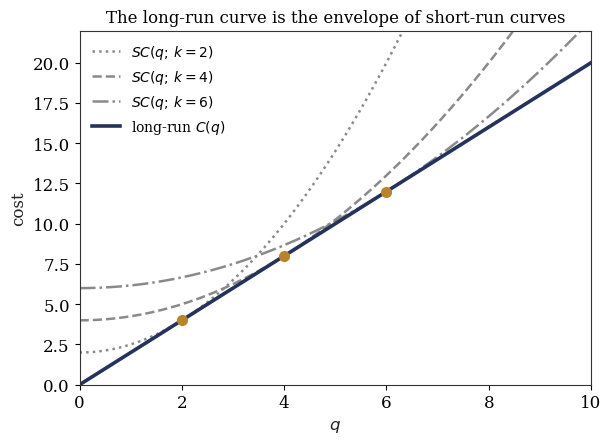

In [10]:
# Short-run cost curves and their lower envelope, the long-run curve.
# q = sqrt(K L) with w = r = 1:  SC(q; k) = k + q^2 / k ;  LRC(q) = 2q.
q = np.linspace(0, 10, 400)
fig, ax = plt.subplots(figsize=(6.6, 4.6))
for k, style in [(2, ":"), (4, "--"), (6, "-.")]:
    ax.plot(q, k + q**2 / k, color=GREY, lw=1.8, ls=style, label=f"$SC(q;\\,k={k})$")
    qt = k                                   # SC is tangent to LRC where q = k
    ax.plot(qt, 2 * qt, "o", color=AMBER, ms=7, zorder=5)
ax.plot(q, 2 * q, color=NAVY, lw=2.6, label="long-run $C(q)$")
ax.set_xlim(0, 10); ax.set_ylim(0, 22)
ax.set_xlabel("$q$"); ax.set_ylabel("cost")
ax.legend(frameon=False, fontsize=10, loc="upper left")
ax.set_title("The long-run curve is the envelope of short-run curves", fontsize=12)
savefig(fig, "short-run-long-run-envelope.png")
plt.show()

## Profit maximization

Inverse demand $p(q) = 10 - q$ and cost $c(q) = \tfrac12 q^2$, so
$\pi(q) = 10q - \tfrac32 q^2$ and $q^* = 10/3$.

saved ..\slides\03_production-optimization\figs\profit-max-panel.png


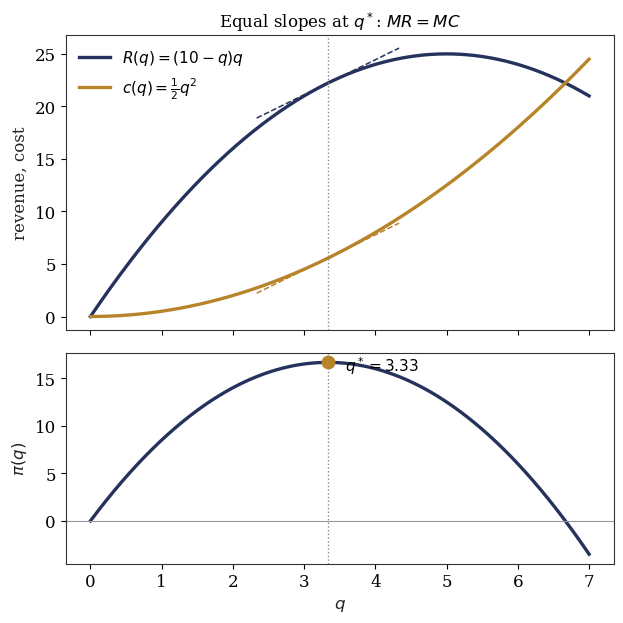

q* = 3.3333,  pi* = 16.6667


In [11]:
q = np.linspace(0, 7, 400)
R = 10 * q - q**2
C = 0.5 * q**2
PI = R - C
qstar = 10 / 3

fig, axes = plt.subplots(2, 1, figsize=(6.4, 6.4), sharex=True,
                         gridspec_kw={"height_ratios": [1.4, 1]})
axes[0].plot(q, R, color=NAVY, lw=2.4, label="$R(q) = (10-q)q$")
axes[0].plot(q, C, color=AMBER, lw=2.4, label=r"$c(q) = \frac{1}{2} q^2$")
for y0, col in [(10 * qstar - qstar**2, NAVY), (0.5 * qstar**2, AMBER)]:
    seg = np.linspace(qstar - 1.0, qstar + 1.0, 2)
    slope = 10 - 2 * qstar if col == NAVY else qstar
    axes[0].plot(seg, y0 + slope * (seg - qstar), color=col, lw=1.1, ls="--")
axes[0].axvline(qstar, color=GREY, lw=1, ls=":")
axes[0].legend(frameon=False, fontsize=11, loc="upper left")
axes[0].set_ylabel("revenue, cost")
axes[0].set_title("Equal slopes at $q^*$: $MR = MC$", fontsize=12)

axes[1].plot(q, PI, color=NAVY, lw=2.4)
axes[1].axvline(qstar, color=GREY, lw=1, ls=":")
axes[1].plot(qstar, 10 * qstar - 1.5 * qstar**2, "o", color=AMBER, ms=9, zorder=5)
axes[1].annotate(rf"$q^*={qstar:.2f}$", (qstar, 10 * qstar - 1.5 * qstar**2),
                 textcoords="offset points", xytext=(12, -6), fontsize=11)
axes[1].axhline(0, color="#999999", lw=0.8)
axes[1].set_xlabel("$q$"); axes[1].set_ylabel(r"$\pi(q)$")
fig.tight_layout()
savefig(fig, "profit-max-panel.png")
plt.show()
print(f"q* = {qstar:.4f},  pi* = {10*qstar - 1.5*qstar**2:.4f}")

saved ..\slides\03_production-optimization\figs\ar-mr-linear.png


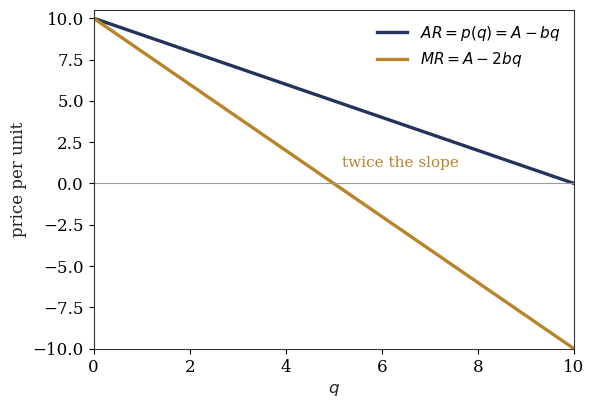

In [12]:
# Linear demand: marginal revenue falls twice as fast as price.
A, b = 10.0, 1.0
q = np.linspace(0, 10, 300)
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.plot(q, A - b * q, color=NAVY, lw=2.4, label="$AR = p(q) = A - bq$")
ax.plot(q, A - 2 * b * q, color=AMBER, lw=2.4, label="$MR = A - 2bq$")
ax.axhline(0, color="#999999", lw=0.8)
ax.annotate("twice the slope", (A / (2 * b), 0), textcoords="offset points",
            xytext=(6, 12), fontsize=11, color=AMBER)
ax.set_xlim(0, 10); ax.set_ylim(-10, 10.5)
ax.set_xlabel("$q$"); ax.set_ylabel("price per unit")
ax.legend(frameon=False, fontsize=11)
savefig(fig, "ar-mr-linear.png")
plt.show()

saved ..\slides\03_production-optimization\figs\supply-and-shutdown.png


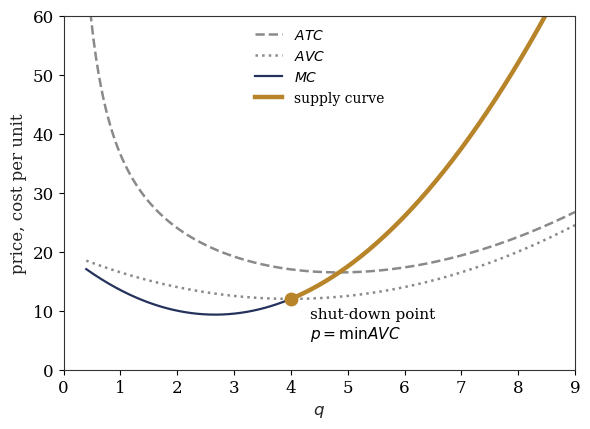

min AVC = 12.00 at q = 4.00


In [13]:
# The competitive firm's supply curve: MC above minimum AVC.
q = np.linspace(0.4, 9, 400)
MC = 1.5 * q**2 - 8 * q + 20
AVC = 0.5 * q**2 - 4 * q + 20
ATC = AVC + 20 / q
qs = q[np.nanargmin(AVC)]
shut = AVC.min()

fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.plot(q, ATC, color=GREY, lw=1.8, ls="--", label="$ATC$")
ax.plot(q, AVC, color=GREY, lw=1.8, ls=":", label="$AVC$")
ax.plot(q, MC, color=NAVY, lw=1.6, label="$MC$")
above = q >= qs
ax.plot(q[above], MC[above], color=AMBER, lw=3.2, label="supply curve")
ax.plot(qs, shut, "o", color=AMBER, ms=9, zorder=6)
ax.annotate("shut-down point\n$p = \\min AVC$", (qs, shut),
            textcoords="offset points", xytext=(14, -28), fontsize=11)
ax.set_xlim(0, 9); ax.set_ylim(0, 60)
ax.set_xlabel("$q$"); ax.set_ylabel("price, cost per unit")
ax.legend(frameon=False, fontsize=10, loc="upper center")
savefig(fig, "supply-and-shutdown.png")
plt.show()
print(f"min AVC = {shut:.2f} at q = {qs:.2f}")